# Follower (hydrostatic) pressure

A pressure added with `follower=True` in `Shell.add_pressure_load` stays normal to the deformed mid-surface and acts on its deformed area, like the pressure of a fluid. This example shows how such a pressure enters the linear buckling, non-linear static, linear static and vibration analyses of `panels`, and compares the results with the literature:

1. the buckling of a ring under three kinds of pressure, against the analytical values of Pflüger (1975) and Schweizerhof and Ramm (1984), and against the closed form of the ring with the same kinematics;
2. the buckling of long sandwich cylinders, against the shell formulas and the elasticity solution of Han, Kardomateas and Simitses (2004);
3. a non-linear static analysis with the Newton-Raphson method of `structsolve`, its load-deflection paths and the convergence of its residuals;
4. a linear static analysis with the follower load;
5. the kinetic stability criterion for a cantilever cylinder with a free edge, whose load stiffness is unsymmetric, against Table 4 of Schweizerhof and Ramm (1984).

**The load stiffness.** The virtual work of a pressure $p$ on the deformed surface $S$ with the outward unit normal $\boldsymbol{n}$ is $-\int_S p\,\boldsymbol{n}\cdot\delta\boldsymbol{u}\,dS$. Since $\boldsymbol{n}\,dS$ depends on the displacements, its linearization gives, besides the load vector, a *load stiffness*. Hibbitt (1979, pp. 938-939) showed that for a uniform pressure the load stiffness is the sum of a symmetric surface integral and of an antisymmetric integral over the boundary of the loaded surface: it is symmetric when the boundary terms vanish, e.g. on a closed surface or where the displacements of the boundary are prescribed, and unsymmetric at free edges or where the pressure changes. Schweizerhof and Ramm (1984, Table 2) list these conditions for the different kinds of pressure loads.

In `panels`, the part of the follower force vector that depends on the configuration enters `Shell.calc_fint`, and its derivative, the load stiffness `Shell.calc_kCfollower`, enters `Shell.calc_kT`, both at the load factor `inc`. In the undeformed state the follower pressure equals the dead load returned by `Shell.calc_fext`. The theory, with the truncations of the area vector, is in [Follower pressure loads: theory](../follower_pressure.rst).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import Analysis, freq, lb, solve, static
from panels.shell import Shell

# models, closed forms and data of the literature of the validation tests
import follower_utils
val = follower_utils.val


def results_table(rows):
    # Markdown table of (quantity, panels, reference, source) rows
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, value, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, value, ref, (value - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def fold(theta, sector):
    # angle in [0, sector] of the point theta of a structure symmetric with
    # respect to the planes theta = k*sector (the modelled sector repeated
    # by reflection)
    phi = np.mod(theta, 2*sector)
    return np.where(phi > sector, 2*sector - phi, phi)

## 1. Linear buckling of a ring

### The eigenvalue problem

The pre-buckling state $\boldsymbol{c}_0$ is the linear static solution under a unit external pressure. With a follower pressure, the load stiffness $\boldsymbol{K}_{C,follower}$ is added to the geometric stiffness $\boldsymbol{K}_G(\boldsymbol{c}_0)$ in the linear buckling problem

$$
\left(\boldsymbol{K}_C + \lambda \left(\boldsymbol{K}_G(\boldsymbol{c}_0) + \boldsymbol{K}_{C,follower}\right)\right)\boldsymbol{c} = \boldsymbol{0},
$$

solved with `structsolve.lb`, which uses the solvers of unsymmetric matrices when needed. A dead load (constant direction) has no load stiffness. A centrally directed pressure, always pointing to the centre of the ring, has a load stiffness that `panels` does not implement; for the comparison it is integrated by `central_load_stiffness` of the validation tests.

### The model of the ring

A long cylinder under a uniform pressure buckles as a ring, in plane strain. It is modelled with a quarter of the circumference, $b = \pi r/2$, and a short length $a = r/2$. The ends $x = 0, a$ are in generalized plane strain: $u$ and the slopes $v_{,x}$, $w_{,x}$ are constrained, and so is the rotation $\phi_x$ of the shear deformation theories. The straight edges are symmetry planes of the modes $w \propto \cos(n y/r)$ with $n$ even: $v$, $w_{,y}$ and $\phi_y$ are constrained.

In [2]:
def ring_shell(model, R, stack, plyts, laminaprops, m=4, n=15, **kwargs):
    s = Shell(model=model, **kwargs)
    s.r = R
    s.a = 0.5*R
    s.b = np.pi/2*R
    s.stack = list(stack)
    s.plyts = list(plyts)
    s.laminaprops = list(laminaprops)
    s.m = m
    s.n = n
    for e in ('x1', 'x2', 'y1', 'y2'):
        for f in 'uvw':
            setattr(s, e + f, 1.)
            setattr(s, e + f + 'r', 1.)
    s.x1u = s.x2u = 0.
    s.x1vr = s.x2vr = 0.
    s.x1wr = s.x2wr = 0.
    s.y1v = s.y2v = 0.
    s.y1wr = s.y2wr = 0.
    s.x1phiy = s.x2phiy = 1.
    s.x1phix = s.x2phix = 0.
    s.y1phix = s.y2phix = 1.
    s.y1phiy = s.y2phiy = 0.
    return s


def buckling_pressure(s, load='follower', zp=0.):
    # critical external pressure and mode of a dead, follower or centrally
    # directed pressure acting on the surface z = zp
    s.clear_loads()
    s.add_pressure_load(-1., cte=False, follower=(load == 'follower'), zp=zp)
    k0 = s.calc_kC()
    c0 = solve(k0, s.calc_fext(), silent=True)
    K = s.calc_kG(c=c0)
    if load == 'follower':
        K = K + s.calc_kCfollower()
    elif load == 'central':
        K = K + val.central_load_stiffness(s, -1.*(1 + zp/s.r))
    eigvals, eigvecs = lb(k0, K, silent=True, num_eigvalues=4)
    return np.real(eigvals[0]), np.real(eigvecs[:, 0])

### Isotropic ring: three kinds of pressure

The ring has $r = 1$ m and $h = 0.01$ m and is made of aluminium, $E = 70$ GPa, $\nu = 0.3$. It is analysed with the classical (CLPT) and first-order shear deformation (FSDT, shear correction factor 5/6) theories, each with Sanders' and Donnell's kinematics.

**Literature.** For an inextensible ring under a uniform pressure, $q_K = 3EI/r^3$ when the load stays normal to the ring axis (the follower, or hydrostatic, pressure), $4EI/r^3$ when it keeps its direction, and $4.50EI/r^3$ when it is directed to the centre of the ring: Pflüger (1975), p. 403, case I, D, b, 1. Schweizerhof and Ramm (1984), Table 3, p. 1108, give the same analytical values, $k = 3.000$, $4.000$ and $4.500$ with $p_{cr} = k EI/R^3$. For the long cylinder in plane strain, $EI$ per unit length is the bending stiffness $D = D_{22} = E h^3/(12(1 - \nu^2))$, so $p_{cr} r^3/D$ is compared with $k$. With $r/h = 100$, the extensibility of the ring and the transverse shear change these values by about $(h/r)^2 = 10^{-4}$.

**Closed form of the discrete theory.** For the ring mode $n$, the second variation of the total potential energy of the same kinematic theory reduces to a small eigenvalue problem in the amplitudes of $w$, $v$ and, for the FSDT, of the rotation; its smallest root is the closed form `ring_closed_form` of the validation tests (`tests/tests_shell/test_follower_pressure_validation.py`), which `panels` reproduces to the error of the discretization. Donnell's kinematics neglect $v/r$ in the rotation, and their inextensional limit, the closed form with a very large membrane stiffness, is not 3 and 4.5 but 16/5 and 64/15, the known inaccuracy of Donnell's theory for low $n$; no literature value is compared for them.

In [3]:
K_TABLE3 = {'follower': 3.000, 'dead': 4.000, 'central': 4.500}
SRC_TABLE3 = 'Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403'
models = ['cylshell_clpt_sanders', 'cylshell_clpt_donnell',
          'cylshell_fsdt_sanders', 'cylshell_fsdt_donnell']
ring = {}
for model in models:
    kin = 'sanders' if 'sanders' in model else 'donnell'
    for load in ['follower', 'dead', 'central']:
        s = ring_shell(model, 1., [0.], [0.01], [val.ISO],
                       fsdt_shear_correction=5/6)
        p_cr, mode = buckling_pressure(s, load)
        A22, D22 = s.ABD[1, 1], s.ABD[4, 4]
        S = s.ABD[6, 6] if 'fsdt' in model else None
        closed = -val.ring_closed_form(kin, load, 2, A22, D22, s.r, S)
        inext = -val.ring_closed_form(kin, load, 2, 1.e6*A22, D22, s.r)*s.r**3/D22
        ring[(model, load)] = dict(p_cr=p_cr, k=p_cr*s.r**3/D22, closed=closed,
                                   inext=inext, shell=s, mode=mode)
        print('%-22s %-8s p_cr = %10.3f Pa, p_cr r^3/D = %.5f, inextensional closed form %.5f'
              % (model, load, p_cr, p_cr*s.r**3/D22, inext))

cylshell_clpt_sanders  follower p_cr =  19230.609 Pa, p_cr r^3/D = 2.99998, inextensional closed form 3.00000
cylshell_clpt_sanders  dead     p_cr =  25641.026 Pa, p_cr r^3/D = 4.00000, inextensional closed form 3.99997
cylshell_clpt_sanders  central  p_cr =  28846.094 Pa, p_cr r^3/D = 4.49999, inextensional closed form 4.49996
cylshell_clpt_donnell  follower p_cr =  20512.711 Pa, p_cr r^3/D = 3.19998, inextensional closed form 3.20000
cylshell_clpt_donnell  dead     p_cr =  25641.026 Pa, p_cr r^3/D = 4.00000, inextensional closed form 4.00000
cylshell_clpt_donnell  central  p_cr =  27350.411 Pa, p_cr r^3/D = 4.26666, inextensional closed form 4.26666


cylshell_fsdt_sanders  follower p_cr =  19228.411 Pa, p_cr r^3/D = 2.99963, inextensional closed form 3.00000
cylshell_fsdt_sanders  dead     p_cr =  25638.096 Pa, p_cr r^3/D = 3.99954, inextensional closed form 3.99997
cylshell_fsdt_sanders  central  p_cr =  28842.797 Pa, p_cr r^3/D = 4.49948, inextensional closed form 4.49996


cylshell_fsdt_donnell  follower p_cr =  20510.367 Pa, p_cr r^3/D = 3.19962, inextensional closed form 3.20000
cylshell_fsdt_donnell  dead     p_cr =  25638.096 Pa, p_cr r^3/D = 3.99954, inextensional closed form 4.00000
cylshell_fsdt_donnell  central  p_cr =  27347.286 Pa, p_cr r^3/D = 4.26618, inextensional closed form 4.26666


The table compares each critical pressure with the closed form of its theory, and $p_{cr} r^3/D$ of Sanders' kinematics with the analytical values of the literature:

In [4]:
rows = []
for (model, load), res in ring.items():
    rows.append(('`%s`, %s, $p_{cr}$ (Pa)' % (model, load), res['p_cr'], res['closed'],
                 'closed form of the same theory, mode $n = 2$'))
    if 'sanders' in model:
        rows.append(('`%s`, %s, $p_{cr} r^3/D$' % (model, load), res['k'],
                     K_TABLE3[load], SRC_TABLE3))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `cylshell_clpt_sanders`, follower, $p_{cr}$ (Pa) | 19230.6 | 19230.6 | +6.60e-12 | closed form of the same theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, follower, $p_{cr} r^3/D$ | 2.99998 | 3 | -8.33e-06 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_clpt_sanders`, dead, $p_{cr}$ (Pa) | 25641 | 25641 | +2.75e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, dead, $p_{cr} r^3/D$ | 4 | 4 | +2.56e-11 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_clpt_sanders`, central, $p_{cr}$ (Pa) | 28846.1 | 28846.1 | +2.34e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_clpt_sanders`, central, $p_{cr} r^3/D$ | 4.49999 | 4.5 | -2.08e-06 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_clpt_donnell`, follower, $p_{cr}$ (Pa) | 20512.7 | 20512.7 | -2.97e-12 | closed form of the same theory, mode $n = 2$ |
| `cylshell_clpt_donnell`, dead, $p_{cr}$ (Pa) | 25641 | 25641 | +7.46e-12 | closed form of the same theory, mode $n = 2$ |
| `cylshell_clpt_donnell`, central, $p_{cr}$ (Pa) | 27350.4 | 27350.4 | +7.77e-12 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, follower, $p_{cr}$ (Pa) | 19228.4 | 19228.4 | -1.08e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, follower, $p_{cr} r^3/D$ | 2.99963 | 3 | -1.23e-04 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_fsdt_sanders`, dead, $p_{cr}$ (Pa) | 25638.1 | 25638.1 | -5.87e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, dead, $p_{cr} r^3/D$ | 3.99954 | 4 | -1.14e-04 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_fsdt_sanders`, central, $p_{cr}$ (Pa) | 28842.8 | 28842.8 | -4.60e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_sanders`, central, $p_{cr} r^3/D$ | 4.49948 | 4.5 | -1.16e-04 | Schweizerhof and Ramm (1984), Table 3, p. 1108; Pflüger (1975), p. 403 |
| `cylshell_fsdt_donnell`, follower, $p_{cr}$ (Pa) | 20510.4 | 20510.4 | -1.77e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_donnell`, dead, $p_{cr}$ (Pa) | 25638.1 | 25638.1 | -5.24e-11 | closed form of the same theory, mode $n = 2$ |
| `cylshell_fsdt_donnell`, central, $p_{cr}$ (Pa) | 27347.3 | 27347.3 | -2.77e-11 | closed form of the same theory, mode $n = 2$ |

### Buckling mode

The buckling mode is the oval mode $n = 2$. The modelled quarter is repeated by reflection about its symmetry planes to draw the whole ring, with the radial displacement $w$ magnified; along the quarter, $w$ follows $\cos(2y/r)$.

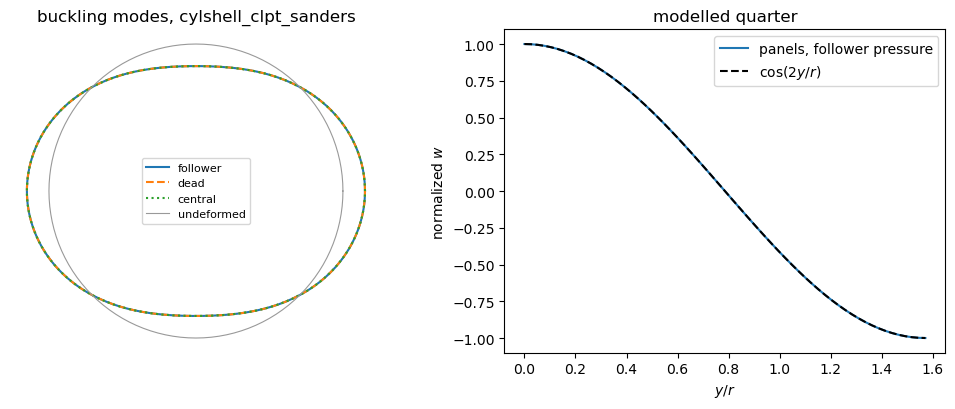

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.2))
theta = np.linspace(0, 2*np.pi, 241)
ax = axes[0]
for load, style in (('follower', '-'), ('dead', '--'), ('central', ':')):
    res = ring[('cylshell_clpt_sanders', load)]
    s = res['shell']
    ys = s.r*fold(theta, np.pi/2)
    s.uvw(res['mode'], xs=np.full_like(ys, s.a/2), ys=ys)
    w = s.fields['w']/np.abs(s.fields['w']).max()
    rr = s.r + 0.15*s.r*w*np.sign(w[0])
    ax.plot(rr*np.cos(theta), rr*np.sin(theta), style, label=load)
ax.plot(s.r*np.cos(theta), s.r*np.sin(theta), color='0.6', lw=0.8,
        label='undeformed')
ax.set_aspect('equal')
ax.set_title('buckling modes, cylshell_clpt_sanders')
ax.legend(fontsize=8, loc='center')
ax.axis('off')

ax = axes[1]
res = ring[('cylshell_clpt_sanders', 'follower')]
s = res['shell']
ys = np.linspace(0, s.b, 61)
s.uvw(res['mode'], xs=np.full_like(ys, s.a/2), ys=ys)
w = s.fields['w']/np.abs(s.fields['w']).max()
ax.plot(ys/s.r, w, label='panels, follower pressure')
ax.plot(ys/s.r, np.cos(2*ys/s.r)*np.sign(w[0]), 'k--', label=r'$\cos(2y/r)$')
ax.set_xlabel('$y/r$')
ax.set_ylabel('normalized $w$')
ax.set_title('modelled quarter')
ax.legend()
fig.tight_layout()
plt.show()

## 2. Long sandwich cylinders of Han et al. (2004)

### The problem

Han, Kardomateas and Simitses (2004) compare an elasticity solution and shell formulas for long sandwich cylinders under external pressure. The faces are boron/epoxy, graphite/epoxy or kevlar/epoxy with the fibres in the hoop direction, $f = 0.1$ in thick, and the core is an isotropic alloy foam, $c = 1$ in (Table 1, p. 596). The mean radius is $R_0 = (R_0/h)(2f + c)$ with $R_0/h$ = 15, 30, 60 and 120. The material data and the reference values are those of the validation tests (`val.FACES`, `val.CORE`, `val.HAN2004`, `val.HAN2004_CLASSICAL`), read in Tables 1 and 2 of the paper.

### The shell formulas

Their shell formulas (p. 596) are those of the inextensible ring, all for the mode $n = 2$. Without transverse shear, the classical formula, Eq. (12a), is $p_{cl} = 3(EI)_{eq}/(BR_0^3)$, with the bending stiffness of the sandwich of width $B$ of Eq. (12b), computed with the hoop modulus $E_f$ of the faces. With the transverse shear, Eq. (13a),

$$
p_{w/shear} = \frac{3(EI)_{eq}}{BR_0^3(1 + 4k_s)}, \qquad k_s = \frac{(EI)_{eq}}{CR_0^2},
$$

with the shear stiffness $C$ of the section, Eq. (13b), taken as that of the core only, $C = BcG_{12}^c$, Eq. (14a), or as that of an effective shear modulus $\bar{G}$ of the whole section, $(2f + c)/\bar{G} = 2f/G_{12}^f + c/G_{12}^c$, Eqs. (14b) and (14c).

### The models of `panels`

The classical formula is compared with the ring of `cylshell_clpt_sanders`. The two shear formulas are compared with the ring of `cylshell_fsdt_sanders` given the same transverse shear stiffness per unit width, $C/B$, through `fsdt_shear_correction` (`sandwich_ring` and `han_shear_stiffness` of the validation tests). The 3-ply laminate $[90_f/0_c/90_f]$ has its fibres along the circumference, $y$. With the follower pressure on the mid-surface, the FSDT ring is the formula (13a) in the inextensional limit. Two differences remain: the formulas use the modulus $E_f$ of the faces, while `panels` uses the plane-strain bending stiffness $D_{22}$ of the laminate, larger by the factor $1/(1 - \nu_{12}\nu_{21})$ of the faces (printed below); and the formulas neglect the extensibility of the ring, which lowers the critical pressure by about $(h/R_0)^2$, 0.4% at $R_0/h = 15$.

In [6]:
HAN_RATIOS = np.array(val.RATIOS)
FACES = ['boron', 'graphite', 'kevlar']
han = {}
for face in FACES:
    han[(face, 'CLPT')] = [buckling_pressure(
        val.sandwich_ring(face, ratio, model='cylshell_clpt_sanders'))[0]
        for ratio in val.RATIOS]
    for kind in ('core', 'Gbar'):
        S = val.han_shear_stiffness(face, kind)
        han[(face, kind)] = [buckling_pressure(
            val.sandwich_ring(face, ratio, shear=S))[0]
            for ratio in val.RATIOS]
for face in FACES:
    # D22 of panels against (EI)eq/B of Eq. (12b), with the hoop modulus E_f
    f, c, Ef, Ec = val.F, val.C, val.FACES[face][0], val.CORE[0]
    EI_B = Ef*f**3/6 + 2*Ef*f*(f/2 + c/2)**2 + Ec*c**3/12
    D22 = val.sandwich_ring(face, 15).ABD[4, 4]
    print('%-8s D22/((EI)eq/B) - 1 = %+.2f%%' % (face, 100*(D22/EI_B - 1)))
for face in FACES:
    for i, ratio in enumerate(val.RATIOS):
        print('%-8s R0/h = %3d: p_cr (Pa) CLPT %10.0f, FSDT core shear %9.0f, FSDT Gbar %9.0f'
              % (face, ratio, han[(face, 'CLPT')][i], han[(face, 'core')][i],
                 han[(face, 'Gbar')][i]))

boron    D22/((EI)eq/B) - 1 = +0.50%
graphite D22/((EI)eq/B) - 1 = +0.45%
kevlar   D22/((EI)eq/B) - 1 = +0.86%
boron    R0/h =  15: p_cr (Pa) CLPT    6926848, FSDT core shear    651374, FSDT Gbar    900244
boron    R0/h =  30: p_cr (Pa) CLPT     866463, FSDT core shear    254077, FSDT Gbar    323939
boron    R0/h =  60: p_cr (Pa) CLPT     108327, FSDT core shear     67592, FSDT Gbar     76353
boron    R0/h = 120: p_cr (Pa) CLPT      13541, FSDT core shear     11768, FSDT Gbar     12258
graphite R0/h =  15: p_cr (Pa) CLPT    5670709, FSDT core shear    638083, FSDT Gbar    875138
graphite R0/h =  30: p_cr (Pa) CLPT     709336, FSDT core shear    238580, FSDT Gbar    299183
graphite R0/h =  60: p_cr (Pa) CLPT      88683, FSDT core shear     59384, FSDT Gbar     66044
graphite R0/h = 120: p_cr (Pa) CLPT      11086, FSDT core shear      9869, FSDT Gbar     10211
kevlar   R0/h =  15: p_cr (Pa) CLPT    2388681, FSDT core shear    552642, FSDT Gbar    721516
kevlar   R0/h =  30: p_cr (Pa) CLP

The table compares each critical pressure with the shell formula of the same assumptions, Table 2 of Han et al. (2004), p. 597 (in N/m$^2$ = Pa):

In [7]:
rows = []
for face in FACES:
    for i, ratio in enumerate(val.RATIOS):
        rows.append(('%s, $R_0/h = %d$, CLPT, $p_{cr}$ (Pa)' % (face, ratio),
                     han[(face, 'CLPT')][i], val.HAN2004_CLASSICAL[face][i],
                     'Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a)'))
        rows.append(('%s, $R_0/h = %d$, FSDT, core shear, $p_{cr}$ (Pa)' % (face, ratio),
                     han[(face, 'core')][i], val.HAN2004[face][i][1],
                     'Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a)'))
        rows.append(('%s, $R_0/h = %d$, FSDT, $\\bar{G}$ shear, $p_{cr}$ (Pa)' % (face, ratio),
                     han[(face, 'Gbar')][i], val.HAN2004[face][i][2],
                     'Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c)'))
results_table(rows)

| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| boron, $R_0/h = 15$, CLPT, $p_{cr}$ (Pa) | 6.92685e+06 | 6.89874e+06 | +4.07e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| boron, $R_0/h = 15$, FSDT, core shear, $p_{cr}$ (Pa) | 651374 | 651125 | +3.83e-04 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| boron, $R_0/h = 15$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 900244 | 899768 | +5.30e-04 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| boron, $R_0/h = 30$, CLPT, $p_{cr}$ (Pa) | 866463 | 862343 | +4.78e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| boron, $R_0/h = 30$, FSDT, core shear, $p_{cr}$ (Pa) | 254077 | 253721 | +1.40e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| boron, $R_0/h = 30$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 323939 | 323361 | +1.79e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| boron, $R_0/h = 60$, CLPT, $p_{cr}$ (Pa) | 108327 | 107793 | +4.95e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| boron, $R_0/h = 60$, FSDT, core shear, $p_{cr}$ (Pa) | 67591.7 | 67383 | +3.10e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| boron, $R_0/h = 60$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 76352.8 | 76087 | +3.49e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| boron, $R_0/h = 120$, CLPT, $p_{cr}$ (Pa) | 13541.5 | 13474 | +5.01e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| boron, $R_0/h = 120$, FSDT, core shear, $p_{cr}$ (Pa) | 11768.3 | 11717 | +4.38e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| boron, $R_0/h = 120$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 12258.1 | 12203 | +4.51e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| graphite, $R_0/h = 15$, CLPT, $p_{cr}$ (Pa) | 5.67071e+06 | 5.65046e+06 | +3.58e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| graphite, $R_0/h = 15$, FSDT, core shear, $p_{cr}$ (Pa) | 638083 | 637826 | +4.03e-04 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| graphite, $R_0/h = 15$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 875138 | 874654 | +5.53e-04 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| graphite, $R_0/h = 30$, CLPT, $p_{cr}$ (Pa) | 709336 | 706307 | +4.29e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| graphite, $R_0/h = 30$, FSDT, core shear, $p_{cr}$ (Pa) | 238580 | 238236 | +1.44e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| graphite, $R_0/h = 30$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 299183 | 298643 | +1.81e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| graphite, $R_0/h = 60$, CLPT, $p_{cr}$ (Pa) | 88682.5 | 88288 | +4.47e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| graphite, $R_0/h = 60$, FSDT, core shear, $p_{cr}$ (Pa) | 59383.9 | 59207 | +2.99e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| graphite, $R_0/h = 60$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 66043.6 | 65825 | +3.32e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| graphite, $R_0/h = 120$, CLPT, $p_{cr}$ (Pa) | 11085.8 | 11036 | +4.51e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| graphite, $R_0/h = 120$, FSDT, core shear, $p_{cr}$ (Pa) | 9868.52 | 9829 | +4.02e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| graphite, $R_0/h = 120$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 10210.7 | 10168 | +4.20e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| kevlar, $R_0/h = 15$, CLPT, $p_{cr}$ (Pa) | 2.38868e+06 | 2.37059e+06 | +7.63e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| kevlar, $R_0/h = 15$, FSDT, core shear, $p_{cr}$ (Pa) | 552642 | 551668 | +1.76e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| kevlar, $R_0/h = 15$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 721516 | 719856 | +2.31e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| kevlar, $R_0/h = 30$, CLPT, $p_{cr}$ (Pa) | 298794 | 296324 | +8.34e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| kevlar, $R_0/h = 30$, FSDT, core shear, $p_{cr}$ (Pa) | 163172 | 162433 | +4.55e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| kevlar, $R_0/h = 30$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 189342 | 188347 | +5.28e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| kevlar, $R_0/h = 60$, CLPT, $p_{cr}$ (Pa) | 37355.8 | 37040 | +8.53e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| kevlar, $R_0/h = 60$, FSDT, core shear, $p_{cr}$ (Pa) | 30928.2 | 30712 | +7.04e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| kevlar, $R_0/h = 60$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 32638.2 | 32397 | +7.45e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |
| kevlar, $R_0/h = 120$, CLPT, $p_{cr}$ (Pa) | 4669.68 | 4630 | +8.57e-03 | Han et al. (2004), Table 2, p. 597, classical shell, Eq. (12a) |
| kevlar, $R_0/h = 120$, FSDT, core shear, $p_{cr}$ (Pa) | 4439.04 | 4403 | +8.18e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14a) |
| kevlar, $R_0/h = 120$, FSDT, $\bar{G}$ shear, $p_{cr}$ (Pa) | 4506.82 | 4470 | +8.24e-03 | Han et al. (2004), Table 2, p. 597, shell with shear, Eqs. (13a), (14b), (14c) |

The critical pressures against $R_0/h$ (top) with the shell formulas (markers) and the elasticity solution of Han et al. (2004, Table 2) (crosses), and the relative difference of `panels` from the shell formula of the same assumptions (bottom). The transverse shear of the soft core lowers the critical pressure of the thick cylinders by up to an order of magnitude; the elasticity solution lies between the two shear formulas.

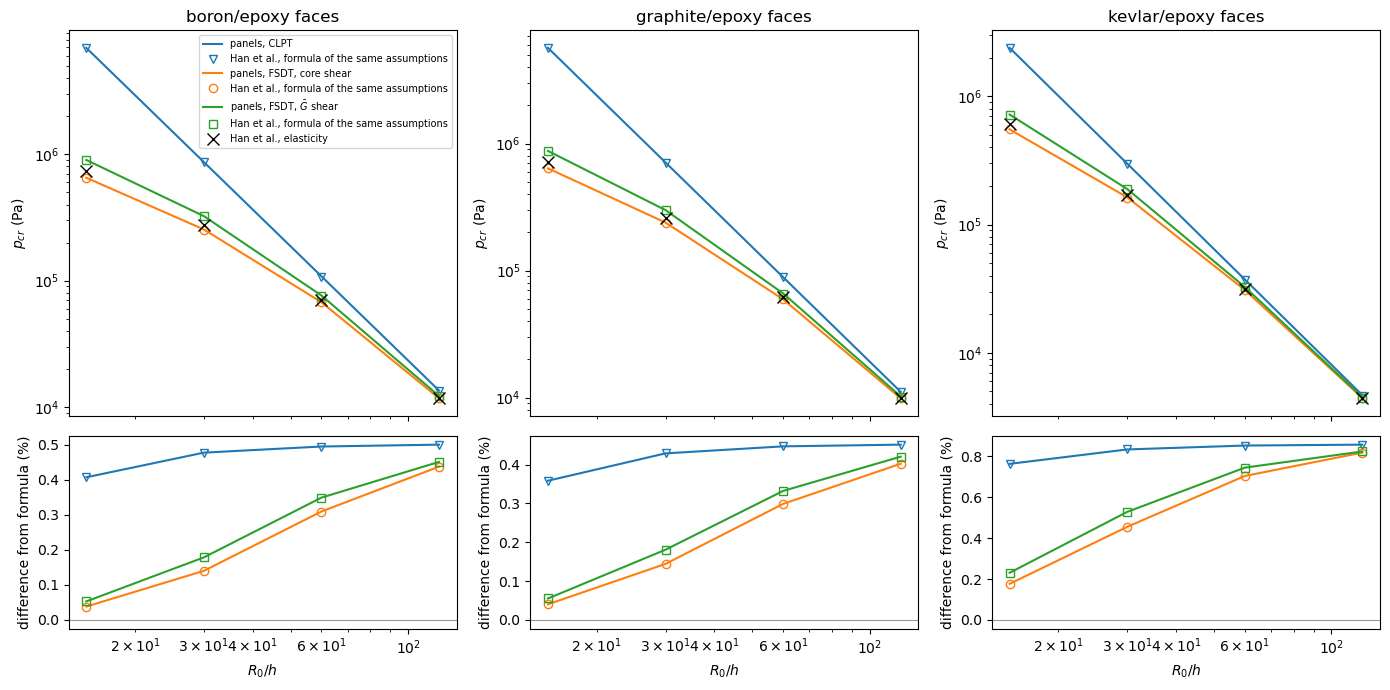

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7), sharex=True,
                         gridspec_kw=dict(height_ratios=[2, 1]))
cases = (('CLPT', 'CLPT', np.array([val.HAN2004_CLASSICAL[f] for f in FACES]), 'v'),
         ('core', 'FSDT, core shear', None, 'o'),
         ('Gbar', r'FSDT, $\bar{G}$ shear', None, 's'))
for j, face in enumerate(FACES):
    data = np.array(val.HAN2004[face])
    refs = {'CLPT': np.array(val.HAN2004_CLASSICAL[face]),
            'core': data[:, 1], 'Gbar': data[:, 2]}
    ax, axd = axes[0, j], axes[1, j]
    for (key, label, _, style), color in zip(cases, ['C0', 'C1', 'C2']):
        ax.loglog(HAN_RATIOS, han[(face, key)], '-', color=color,
                  label='panels, %s' % label)
        ax.loglog(HAN_RATIOS, refs[key], style, color=color, mfc='none',
                  label='Han et al., formula of the same assumptions')
        axd.semilogx(HAN_RATIOS, 100*(np.array(han[(face, key)])/refs[key] - 1),
                     style + '-', color=color, mfc='none')
    ax.loglog(HAN_RATIOS, data[:, 0], 'kx', ms=8, label='Han et al., elasticity')
    ax.set_title('%s/epoxy faces' % face)
    ax.set_ylabel('$p_{cr}$ (Pa)')
    axd.axhline(0., color='0.6', lw=0.8)
    axd.set_xlabel('$R_0/h$')
    axd.set_ylabel('difference from formula (%)')
axes[0, 0].legend(fontsize=7)
fig.tight_layout()
plt.show()

## 3. Non-linear static analysis

### The problem

The callables of the `Shell` are passed directly to `structsolve.Analysis`, which passes its load factor to the callables that accept `inc`. With the follower pressure, the internal force vector of `calc_fint` includes the configuration-dependent part of the pressure, and the tangent stiffness matrix of `calc_kT` includes its exact load stiffness, so that the Newton-Raphson iterations converge quadratically.

A panel of $0.3 \times 0.2$ m, a plate or a cylindrical shell of $r = 0.4$ m, has the unsymmetric and unbalanced laminate $[30/-45/0/90]$ of plies of 0.125 mm. Its edges have $w = 0$ and the in-plane rigid-body motions removed. It is loaded by a uniform follower pressure, `follower='quadratic'`, plus a sinusoidal follower pressure on a strip, `follower='linear'`; see `Shell.add_pressure_load` for the two truncations of the area vector. The same pressures as dead loads give the comparison. No literature value exists for this panel: the section shows the analysis. The non-linear follower terms are compared with the literature in the notebook [schweizerhof1984_cantilever_postbuckling.ipynb](schweizerhof1984_cantilever_postbuckling.ipynb), against Fig. 13 of Schweizerhof and Ramm (1984).

The load is applied in ten equal increments. The relative residual $\|\boldsymbol{F}_{int} - \lambda\boldsymbol{F}_{ext}\|/\max(\|\lambda\boldsymbol{F}_{ext}\|, \|\boldsymbol{F}_{int}\|)$ of every iteration is recorded by wrapping `calc_fint`.

In [9]:
def make_shell(model):
    E11 = 142.5e9
    E22 = E11/20
    s = Shell(model=model, a=0.3, b=0.2, m=5, n=5, plyt=0.125e-3,
              stack=[30, -45, 0, 90],
              laminaprop=(E11, E22, 0.25, 0.5*E22, 0.5*E22, 0.5*E22),
              r=0.4 if model.startswith('cylshell') else None)
    s.nx = s.ny = 8
    for edge in ('x1', 'x2', 'y1', 'y2'):
        for field in 'uvw':
            setattr(s, edge + field, 0. if field == 'w' else 1.)
            setattr(s, edge + field + 'r', 1.)
    s.x1u = 0.
    s.y1v = 0.
    return s


def follower_shell(model):
    s = make_shell(model)
    s.add_pressure_load(-8.e3 if model.startswith('cyl') else 1.5e3,
                        follower='quadratic', cte=False)
    s.add_pressure_load(lambda x, y: 2.e3*np.sin(np.pi*x/s.a),
                        y1=0.05, y2=0.15, follower='linear', cte=False)
    return s


def wmax(s, c):
    return np.abs(s.uvw(c, gridx=21, gridy=21)[1]['w']).max()


NL_MODELS = ['plate_clpt_donnell', 'cylshell_clpt_sanders', 'cylshell_fsdt_sanders']
nonlinear = {}
for model in NL_MODELS:
    s = follower_shell(model)
    fext = s.calc_fext()
    calls = []

    def calc_fint(c, inc=1., silent=True, s=s, fext=fext, calls=calls):
        fint = s.calc_fint(c, inc=inc)
        ref = max(np.linalg.norm(inc*fext), np.linalg.norm(fint))
        calls.append((len(an.increments), np.linalg.norm(fint - inc*fext)/ref))
        return fint

    an = Analysis(s.calc_fext, calc_fint, s.calc_kC, s.calc_kG)
    an.initialInc = an.maxInc = 0.1
    an.relTOL = 1.e-12
    an.maxNumIter = 20
    an.static(NLgeom=True, silent=True)
    h = len(s.stack)*s.plyt
    # the same pressures as dead loads
    s_dead = make_shell(model)
    for load in s.pressure_loads_inc:
        s_dead.pressure_loads_inc.append(load[:5])
    an_dead = Analysis(s_dead.calc_fext, s_dead.calc_fint, s_dead.calc_kC,
                       s_dead.calc_kG)
    an_dead.initialInc = an_dead.maxInc = 0.1
    an_dead.static(NLgeom=True, silent=True)
    nonlinear[model] = dict(
        shell=s, h=h, calls=calls, c=an.cs[-1],
        follower=(np.array(an.increments), np.array([wmax(s, c)/h for c in an.cs])),
        dead=(np.array(an_dead.increments),
              np.array([wmax(s_dead, c)/h for c in an_dead.cs])))
    print('%-22s %2d increments, max |w|/h at load factor 1: follower %.3f, dead %.3f'
          % (model, len(an.increments), nonlinear[model]['follower'][1][-1],
             nonlinear[model]['dead'][1][-1]))

plate_clpt_donnell     10 increments, max |w|/h at load factor 1: follower 8.342, dead 8.346


cylshell_clpt_sanders  10 increments, max |w|/h at load factor 1: follower 4.983, dead 4.961


cylshell_fsdt_sanders  10 increments, max |w|/h at load factor 1: follower 4.984, dead 4.962


### Load-deflection paths

The largest deflection over the thickness against the load factor. The plate stiffens strongly by membrane action once its deflection exceeds a few thicknesses, while the curved panels respond almost linearly up to five thicknesses. The follower and the dead pressure give paths that differ by less than 1%, because the rotations of the surface remain moderate.

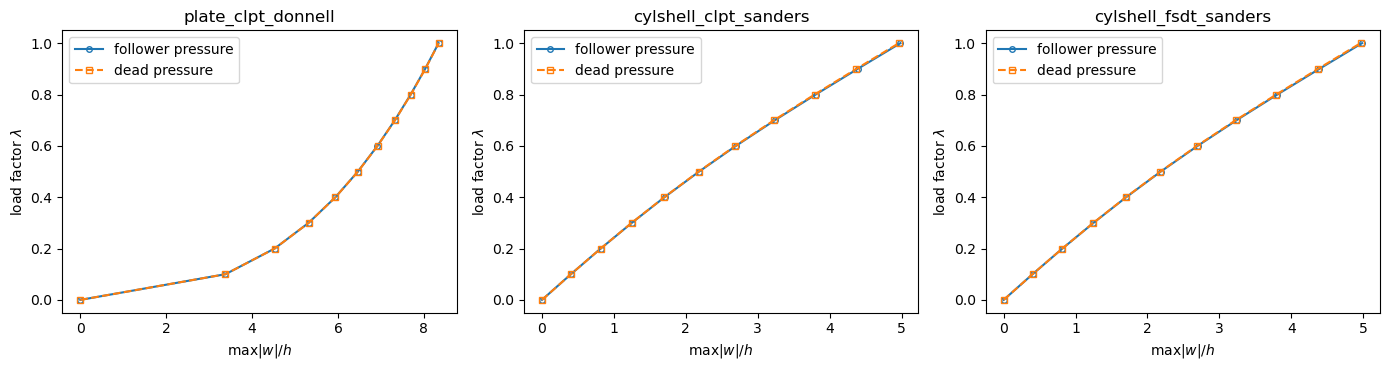

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, model in zip(axes, NL_MODELS):
    for key, style in (('follower', 'o-'), ('dead', 's--')):
        lam, w = nonlinear[model][key]
        ax.plot(np.concatenate(([0.], w)), np.concatenate(([0.], lam)),
                style, ms=4, mfc='none', label='%s pressure' % key)
    ax.set_title(model)
    ax.set_xlabel(r'$\max |w|/h$')
    ax.set_ylabel(r'load factor $\lambda$')
    ax.legend()
fig.tight_layout()
plt.show()

### Convergence of the Newton-Raphson iterations

The relative residual of each iteration, one line per load increment. Once small, the residual is roughly squared at each iteration, the quadratic convergence given by the exact load stiffness in the tangent stiffness matrix.

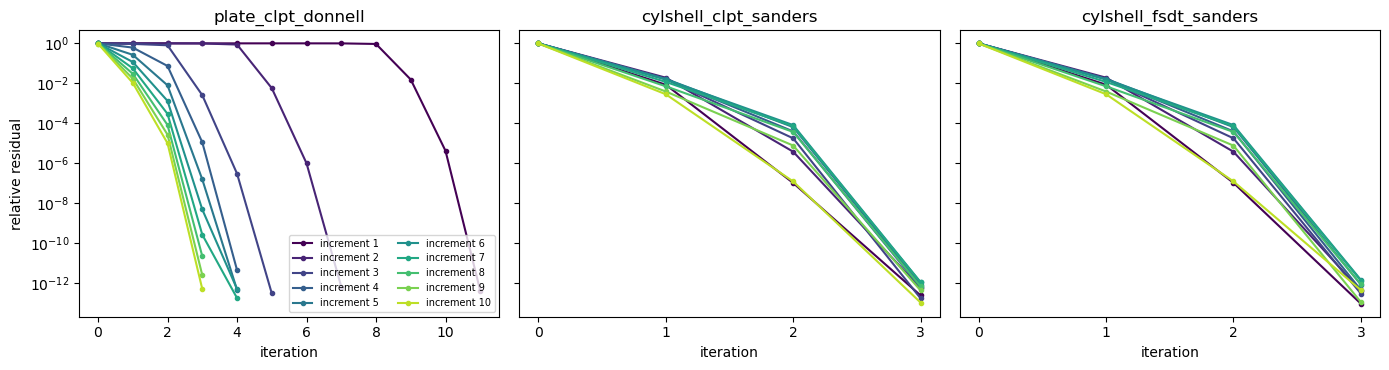

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for ax, model in zip(axes, NL_MODELS):
    calls = nonlinear[model]['calls']
    steps = sorted(set(st for st, e in calls))
    colors = plt.cm.viridis(np.linspace(0, 0.9, len(steps)))
    for step, color in zip(steps, colors):
        errors = [e for st, e in calls if st == step]
        ax.semilogy(errors, 'o-', ms=3, color=color, label='increment %d' % (step + 1))
    ax.set_title(model)
    ax.set_xlabel('iteration')
    ax.xaxis.get_major_locator().set_params(integer=True)
axes[0].set_ylabel('relative residual')
axes[0].legend(fontsize=7, ncol=2)
fig.tight_layout()
plt.show()

### Deformed shapes

The deflection $w$ at the load factor 1 under the follower pressures. The plate deflects as a membrane under the uniform pressure, with its largest deflection shifted towards the strip loaded by the sinusoidal pressure, $0.05 \le y \le 0.15$ m. The curved panels, under external pressure, deflect inwards, $w < 0$, with the largest deflection at about $y = 0.13$ m and a smaller outward bulge near the edge $y = 0$; the unsymmetric laminate and the strip load make the pattern unsymmetric in $y$.

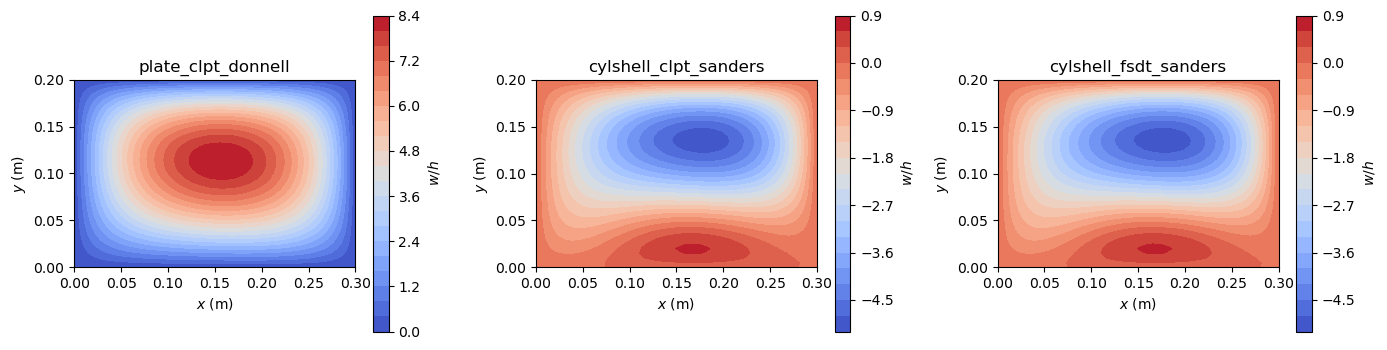

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, model in zip(axes, NL_MODELS):
    s = nonlinear[model]['shell']
    mesh, fields = s.uvw(nonlinear[model]['c'], gridx=61, gridy=41)
    cs_ = ax.contourf(mesh['Xs'], mesh['Ys'], fields['w']/nonlinear[model]['h'], 20,
                      cmap='coolwarm')
    fig.colorbar(cs_, ax=ax, label='$w/h$')
    ax.set_aspect('equal')
    ax.set_title(model)
    ax.set_xlabel('$x$ (m)')
    ax.set_ylabel('$y$ (m)')
fig.tight_layout()
plt.show()

## 4. Linear static analysis

A geometrically linear structure under a follower load solves the unsymmetric system $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$: the load follows the linear deformation. `structsolve.Analysis` does this with `static(NLgeom=False)`, since `Shell.calc_fext` accepts the configuration `c`. The result of `Analysis` is compared with the direct solution of the system above, its algebraic reference, and with the dead-load solution $\boldsymbol{K}_C\boldsymbol{c} = \boldsymbol{F}_{ext}$, to show the effect of the follower terms. The panels of Section 3 carry a uniform pressure of 200 kPa plus 100 kPa to 200 kPa, linearly in $x$, on $x \ge 0.1$ m.

In [13]:
rows = []
for model in ['plate_clpt_donnell', 'cylshell_fsdt_sanders']:
    s = make_shell(model)
    s.add_pressure_load(-2.e5, follower=True, cte=False)
    s.add_pressure_load(lambda x, y: 1.e5*(1 + x/s.a), x1=0.1, follower=True,
                        cte=False)
    an = Analysis(s.calc_fext, s.calc_fint, s.calc_kC, s.calc_kG)
    an.relTOL = 1.e-12
    increments, cs = an.static(NLgeom=False, silent=True)
    k0 = s.calc_kC()
    direct = static(k0 + s.calc_kCfollower(), s.calc_fext(), silent=True)[1][0]
    c_dead = solve(k0, s.calc_fext(), silent=True)
    print('%-22s max |w|: Analysis %.6e m, direct %.6e m, dead load %.6e m (follower/dead = %.4f)'
          % (model, wmax(s, cs[0]), wmax(s, direct), wmax(s, c_dead),
             wmax(s, cs[0])/wmax(s, c_dead)))
    rows.append(('`%s`, largest deflection (m)' % model, wmax(s, cs[0]), wmax(s, direct),
                 'direct solution of $(\\boldsymbol{K}_C + \\boldsymbol{K}_{C,follower})\\boldsymbol{c} = \\boldsymbol{F}_{ext}$'))
results_table(rows)

plate_clpt_donnell     max |w|: Analysis 2.609678e+00 m, direct 2.609678e+00 m, dead load 2.484644e+00 m (follower/dead = 1.0503)


cylshell_fsdt_sanders  max |w|: Analysis 2.424956e-02 m, direct 2.424956e-02 m, dead load 2.310231e-02 m (follower/dead = 1.0497)


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, largest deflection (m) | 2.60968 | 2.60968 | -5.19e-13 | direct solution of $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$ |
| `cylshell_fsdt_sanders`, largest deflection (m) | 0.0242496 | 0.0242496 | +5.22e-12 | direct solution of $(\boldsymbol{K}_C + \boldsymbol{K}_{C,follower})\boldsymbol{c} = \boldsymbol{F}_{ext}$ |

## 5. Kinetic stability criterion of a cantilever cylinder

### Static and kinetic criteria

Schweizerhof and Ramm (1984, p. 1107) define two criteria of stability. The static criterion, Eqs. (52) and (53), is the linear buckling problem of Section 1. The kinetic criterion, Eq. (54), is the eigenvalue problem of the natural frequencies of the loaded structure,

$$
\left(\boldsymbol{K}_C + \lambda\left(\boldsymbol{K}_G(\boldsymbol{c}_0) + \boldsymbol{K}_{C,follower}\right) - \omega^2\boldsymbol{M}\right)\boldsymbol{c} = \boldsymbol{0}.
$$

At a limit or bifurcation point a frequency vanishes, $\omega^2 = 0$, at the load of the static criterion (divergence). Under a non-conservative load, with an unsymmetric load stiffness, the structure may instead lose stability by flutter: two neighbouring frequencies coincide and $\omega^2$ becomes complex; only the kinetic criterion detects it. Purely non-conservative systems fail by flutter only, hybrid ones by either (p. 1107).

### The cantilever cylinder

Shell 1 of Schweizerhof and Ramm (1984, Section 6.4, Fig. 12 and Table 4, p. 1111) is a cylinder with $L/R = 6$ and $R/t = 100$, under uniform follower pressure. Its lower end, condition B1, is hinged with the warping completely restrained ($u = v = w = 0$), and its upper end is free, which makes the load stiffness unsymmetric (Hibbitt, 1979). The buckling mode has $n = 3$ circumferential waves, so a sector of one half wave, $\pi R/3$ (60°), with symmetry planes at its straight edges, is modelled with `cylshell_clpt_sanders` (`schweizerhof_sector` of the validation tests, $R = 100$, $t = 1$). The paper gives $p_{cr} = k\,E t^3/(12(1 - \mu^2)R^3)$, with $k$ independent of $E$. For the kinetic criterion `panels` needs a density; its value scales $\omega^2$ only.

In [14]:
R, t = 100., 1.
s = val.schweizerhof_sector(6*R, R, t, 3, 'B1')
s.rho = 7.8e-9
s._rebuild()
D = val.SCHWEIZERHOF_E*t**3/(12*(1 - val.SCHWEIZERHOF_NU**2))
p_c, _ = buckling_pressure(s, 'dead')
p_f, mode_f = buckling_pressure(s, 'follower')
k_c, k_f = p_c*R**3/D, p_f*R**3/D
print('k_c = %.4f (constant directional pressure), k_f = %.4f (follower pressure)'
      % (k_c, k_f))
Kf = s.calc_kCfollower().toarray()
print('unsymmetric part of the load stiffness: ||K - K^T||/||K|| = %.3f'
      % (np.linalg.norm(Kf - Kf.T)/np.linalg.norm(Kf)))
results_table([
    ('shell 1, B1, $k_c$', k_c, 10.89, 'Schweizerhof and Ramm (1984), Table 4, p. 1111'),
    ('shell 1, B1, $k_f$', k_f, 9.70, 'Schweizerhof and Ramm (1984), Table 4, p. 1111 (symmetrized load stiffness)'),
])

k_c = 10.8764 (constant directional pressure), k_f = 9.6832 (follower pressure)
unsymmetric part of the load stiffness: ||K - K^T||/||K|| = 0.516


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| shell 1, B1, $k_c$ | 10.8764 | 10.89 | -1.25e-03 | Schweizerhof and Ramm (1984), Table 4, p. 1111 |
| shell 1, B1, $k_f$ | 9.68322 | 9.7 | -1.73e-03 | Schweizerhof and Ramm (1984), Table 4, p. 1111 (symmetrized load stiffness) |

### Buckling mode

The mode of the follower pressure, with the modelled sector repeated by reflection around the circumference and the radial displacement magnified: the free upper end ($x = L$) ovalizes into three waves, while the lower end stays circular.

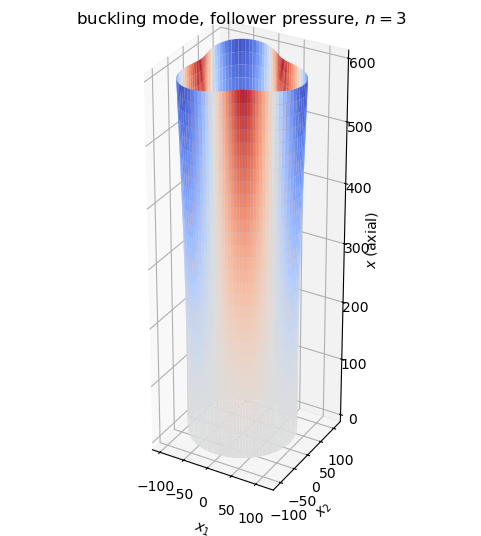

In [15]:
theta = np.linspace(0, 2*np.pi, 121)
xs_ = np.linspace(0, s.a, 31)
TH, XX = np.meshgrid(theta, xs_)
YY = R*fold(TH, s.b/R)
s.uvw(mode_f, xs=XX, ys=YY)
w = s.fields['w']/np.abs(s.fields['w']).max()
rr = R + 0.2*R*w*np.sign(w[-1, 0])
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(rr*np.cos(TH), rr*np.sin(TH), XX, facecolors=plt.cm.coolwarm(0.5 + 0.5*w),
                rstride=1, cstride=1, linewidth=0, shade=False)
ax.set_box_aspect((1, 1, 3))
ax.set_xlabel('$x_1$')
ax.set_ylabel('$x_2$')
ax.set_zlabel('$x$ (axial)')
ax.set_title('buckling mode, follower pressure, $n = 3$')
plt.show()

### Frequencies under increasing pressure

`structsolve.freq` solves the unsymmetric eigenvalue problem of the kinetic criterion with the general dense solver, at fractions of the critical load of the static criterion. The eigenvalue $\omega^2$ of smallest modulus is followed.

p/p_cr = 0.00: lowest omega^2 = 1.714490e+07, imaginary part -4.0e-46
p/p_cr = 0.25: lowest omega^2 = 1.285870e+07, imaginary part +2.1e-15
p/p_cr = 0.50: lowest omega^2 = 8.572485e+06, imaginary part +9.0e-52
p/p_cr = 0.75: lowest omega^2 = 4.286252e+06, imaginary part +5.1e-61
p/p_cr = 0.90: lowest omega^2 = 1.714503e+06, imaginary part -0.0e+00
p/p_cr = 0.95: lowest omega^2 = 8.572517e+05, imaginary part -4.0e-60
p/p_cr = 1.00: lowest omega^2 = 0.000000e+00, imaginary part -0.0e+00


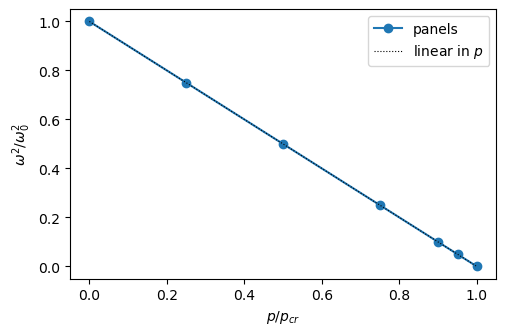

In [16]:
k0 = s.calc_kC()
s.clear_loads()
s.add_pressure_load(-1., cte=False, follower=True)
c0 = solve(k0, s.calc_fext(), silent=True)
KL = s.calc_kG(c=c0) + s.calc_kCfollower()
lam_cr = p_f
kM = s.calc_kM()
fracs = np.array([0., 0.25, 0.5, 0.75, 0.9, 0.95, 1.])
w2 = []
for frac in fracs:
    lambda2 = freq(k0 + frac*lam_cr*KL, kM, silent=True, sparse_solver=False,
                   sort=False)[0]
    finite = lambda2[np.isfinite(lambda2)]
    w2.append(-finite[np.argmin(np.abs(finite))])
w2 = np.array(w2)
for frac, w in zip(fracs, w2):
    print('p/p_cr = %.2f: lowest omega^2 = %.6e, imaginary part %+.1e'
          % (frac, w.real, w.imag))
fig, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(fracs, w2.real/w2[0].real, 'o-', label='panels')
ax.plot([0, 1], [1, 0], 'k:', lw=0.8, label='linear in $p$')
ax.set_xlabel('$p/p_{cr}$')
ax.set_ylabel(r'$\omega^2/\omega_0^2$')
ax.legend()
plt.show()

The lowest $\omega^2$ stays real and decreases linearly with the pressure, since the pre-buckling state is linear, and vanishes at the critical load of the static criterion: the cantilever, a hybrid non-conservative system, loses stability by divergence, not by flutter, and the static criterion applies.

## Discussion

- **Ring.** `panels` reproduces the closed form of its own kinematic theory to the discretization error, for the three kinds of pressure. With Sanders' kinematics, $p_{cr} r^3/D$ is within $2 \times 10^{-4}$ of the analytical values 3, 4 and 4.5 of Pflüger (1975) and Schweizerhof and Ramm (1984, Table 3), the difference being the extensibility of the ring and, for the FSDT, the transverse shear, of the order of $(h/r)^2$. The follower pressure lowers the critical pressure by 25% from the dead load, and the centrally directed pressure raises it by 12.5%. The FE solution of Schweizerhof and Ramm (Table 3: 3.003, 4.004, 4.428) is 1.6% low for the centrally directed load, which they attribute to an approximation of their load stiffness (p. 1108); the load stiffness used here has no such approximation.
- **Sandwich cylinders.** With the shear stiffness of the shell formulas, `panels` is within 1% of the formulas of Han et al. (2004, Table 2) for all faces and $R_0/h$. For the thin cylinders the difference tends to the excess of the plane-strain stiffness $D_{22}$ over the bending stiffness with the modulus $E_f$ of Eq. (12b), printed above; it decreases for the thick cylinders, whose extensibility, neglected by the formulas, lowers the critical pressure. The CLPT reproduces the classical formula, Eq. (12a), within the same 1%, and shows how strongly the shear deformation of the soft core reduces the critical pressure: more than ten times at $R_0/h = 15$ with the boron faces. The elasticity solution lies between the two shear formulas, except for the kevlar faces at $R_0/h = 120$, where it is 0.1% above the effective-modulus formula; its comparison with the default shear corrections of the FSDT and with the TSDT is in [han2004_sandwich_rings.ipynb](han2004_sandwich_rings.ipynb).
- **Non-linear and linear static analyses.** The Newton-Raphson iterations converge quadratically with the follower terms, and `Analysis` with `NLgeom=False` gives the direct solution of the unsymmetric linear system to round-off. The linear follower solution differs from the dead load by about 5% for these panels.
- **Cantilever cylinder.** $k_c$ and $k_f$ of `panels`, a Ritz model with the CLPT and Sanders' kinematics, are within 0.2% of the 16-node shell elements of Schweizerhof and Ramm (Table 4). Their $k_f$ was computed with a symmetrized load stiffness, Eq. (63), while `panels` solves the unsymmetric problem: the agreement confirms their observation that the non-conservative part of the load has a minor influence on the buckling of this shell (p. 1111). The kinetic criterion confirms the divergence.

## Validation notebooks

The comparisons with the literature are extended, per reference, by these notebooks, with the models and the data of `tests/tests_shell/test_follower_pressure_validation.py`:

- [han2004_sandwich_rings.ipynb](han2004_sandwich_rings.ipynb): long sandwich cylinders, Tables 2-4 of Han et al. (2004);
- [kardomateas2003_sandwich_rings.ipynb](kardomateas2003_sandwich_rings.ipynb): Tables 2-4 of Kardomateas and Simitses (2003);
- [kardomateas1993_thick_rings.ipynb](kardomateas1993_thick_rings.ipynb): thick orthotropic and isotropic rings, Tables 1 and 2 and Figs. 2 and 5 of Kardomateas (1993);
- [schweizerhof1984_pressure_loads.ipynb](schweizerhof1984_pressure_loads.ipynb): Tables 2-4 of Schweizerhof and Ramm (1984), rings and cantilever cylinders with an unsymmetric load stiffness;
- [schweizerhof1984_cantilever_postbuckling.ipynb](schweizerhof1984_cantilever_postbuckling.ipynb): the non-linear analysis of the imperfect cantilever, Fig. 13 of Schweizerhof and Ramm (1984);
- [nasa_sp8007_external_pressure.ipynb](nasa_sp8007_external_pressure.ipynb): Batdorf's equations for lateral and hydrostatic pressure of NASA SP-8007 (2020).

## References

1. J.-H. Han, G. A. Kardomateas and G. J. Simitses, "Elasticity, shell theory and finite element results for the buckling of long sandwich cylindrical shells under external pressure". Composites Part B: Engineering, 35:591-598, 2004. https://doi.org/10.1016/j.compositesb.2003.07.002.
2. H. D. Hibbitt, "Some follower forces and load stiffness". International Journal for Numerical Methods in Engineering, 14(6):937-941, 1979.
3. G. A. Kardomateas, "Buckling of thick orthotropic cylindrical shells under external pressure". Journal of Applied Mechanics, 60(1):195-202, 1993. https://doi.org/10.1115/1.2900745.
4. G. A. Kardomateas and G. J. Simitses, "Buckling of long sandwich cylindrical shells under external pressure". In: E. E. Gdoutos and Z. P. Marioli-Riga (eds), Recent Advances in Composite Materials, pp. 291-300, Kluwer Academic Publishers (Springer), Dordrecht, 2003. https://doi.org/10.1007/978-94-017-2852-2_24.
5. NASA, "Buckling of thin-walled circular cylinders". NASA/SP-8007-2020/REV 2, NASA Langley Research Center, 2020. https://ntrs.nasa.gov/citations/20205011530.
6. A. Pflüger, "Stabilitätsprobleme der Elastostatik". 3rd ed., Springer-Verlag, Berlin, Heidelberg, New York, 1975. https://doi.org/10.1007/978-3-662-09994-0.
7. K. Schweizerhof and E. Ramm, "Displacement dependent pressure loads in nonlinear finite element analyses". Computers & Structures, 18(6):1099-1114, 1984. https://doi.org/10.1016/0045-7949(84)90154-8.